# Predictions of interactions with SteadierCom for gut microbiome

In [1]:
import pandas as pd
import numpy as np
import json


import matplotlib as mpl
import seaborn as sns
import matplotlib.pyplot as plt

import sys

sys.path.append("../functions/")

import data.venturelli2018 as data
from analysis.steady_state_flux import steadiercom_samples_plotting
from analysis.compare_metabolomics import processing, plotting
from analysis.compare_glv import processing as processing_glv
from analysis.compare_glv import plotting as plotting_glv
from analysis.abundance_analysis import plotting as plotting_abundance


In [2]:
%load_ext autoreload
%autoreload 2

#### Simulation results

**Loading data for *full community* for different tools**

In [3]:
simulation_dict = data.load_simulated_steadystate_results()


INFO     | load_simulation_results loads simulation results from 
	../output/Venturelli2018/results_steadiercom, 
	../output/Venturelli2018/steadycom and 
	../output/Venturelli2018/smetana
 Only loads results for community 'NONE' (full community)
INFO     | _process_steadystate_result_dict cleans up namespace for the simulation results.


**Load data for *all communities* for steadiercom and smetana**

In [4]:
steadiercom_results_all = data.load_all_steadiercom_steadystate_results()

smetana_all = pd.read_csv("../output/Venturelli2018/smetana/no_coupling_detailed.tsv",sep="\t")
smetana_all = data.abbreviate_member_columns(smetana_all)


INFO     | load_simulation_results loads simulation results from 
	../output/Venturelli2018/results_steadiercom,
 Loads for ALL communities


#### Experimental data

In [5]:
experimental_abundance = data.load_experimental_abundance(all_comms=False)
metabolomics = data.load_metabolomics_data()
glv_data = data.load_glv_data()

INFO     | Loading experimental abundances for FULL community from ../data/Venturelli2018/generated/communities_steadiercom/NONE_abundance.tsv
INFO     | Loading metabolomics data from ../data/Venturelli2018/msb178157-sup-0005-datasetev4.xlsx
INFO     | Loading gLV coefficients from ../data/Venturelli2018/msb178157-sup-0006-codeev1/twelveSpeciesT4.xml


#### Other data

In [6]:
# Load metid2metname dict
with open("../data/Venturelli2018/generated/metid2metname.json",'r') as file:
    metid2metname = json.load(file)
metids_mapped = metid2metname.keys()
# Load: 1. chebi-agora map file and 2. experimental abundance file
metclass2color_dict = {"carbohydrate derivatives":"#DEFD3C",
            "amino acids and derivatives":"#ddaa7b",  
            "nucleotides and derivatives":"#fbdc5d",
            "oligosaccharides":"#8BBDAA",
            "oligopeptides":"#FFD19B",
            "simple sugars":"#9BF276", 
            "urea and urea derivatives":"#FFFFBA",
            "gases":"#b1fbf6", 
            "B-vitamins":"#6F7FB0", 
            "fatty acids":"#ffd1fd",  
            "carboxylic acids and anions":"#EB857E",
            "alcohols and aldehydes":"#C3BBF3", 
            "lipids":"#8FCFFF", 
            "cofactors":"#FF85A1",
            "other":"#eaeaea"
            }

met_chebi_class_agora = pd.read_csv("../data/Venturelli2018/generated/met_chebi_class_agora.tsv",sep="\t",index_col=0)
met_chebi_class_agora["self defined super class"] = met_chebi_class_agora["self defined super class"].map(lambda x: x if x in metclass2color_dict.keys() else "other")
agora_super_class_map = met_chebi_class_agora["self defined super class"].to_dict()

# Colormaps
cmap = ['#a6cee3','#1f78b4', '#b2df8a', '#33a02c', '#fb9a99','#e31a1c', '#fdbf6f', '#ff7f00', '#cab2d6', '#6a3d9a', '#ffff99', '#b15928']
member2color_dict = dict(zip(experimental_abundance.sort_values("member").member.values,cmap))

## Interactions (flux) - SteadyCom vs SteadierCom


#### Fixed growth and abundance
*Description*: bar plots and circos plots

*Main target*
- These plots are made for illustrating the SteadierCom predictions of the steady-state metabolic phenotype.
- Show difference between SteadyCom and SteadierCom: How relative abundance affects predicted in mass flux between members

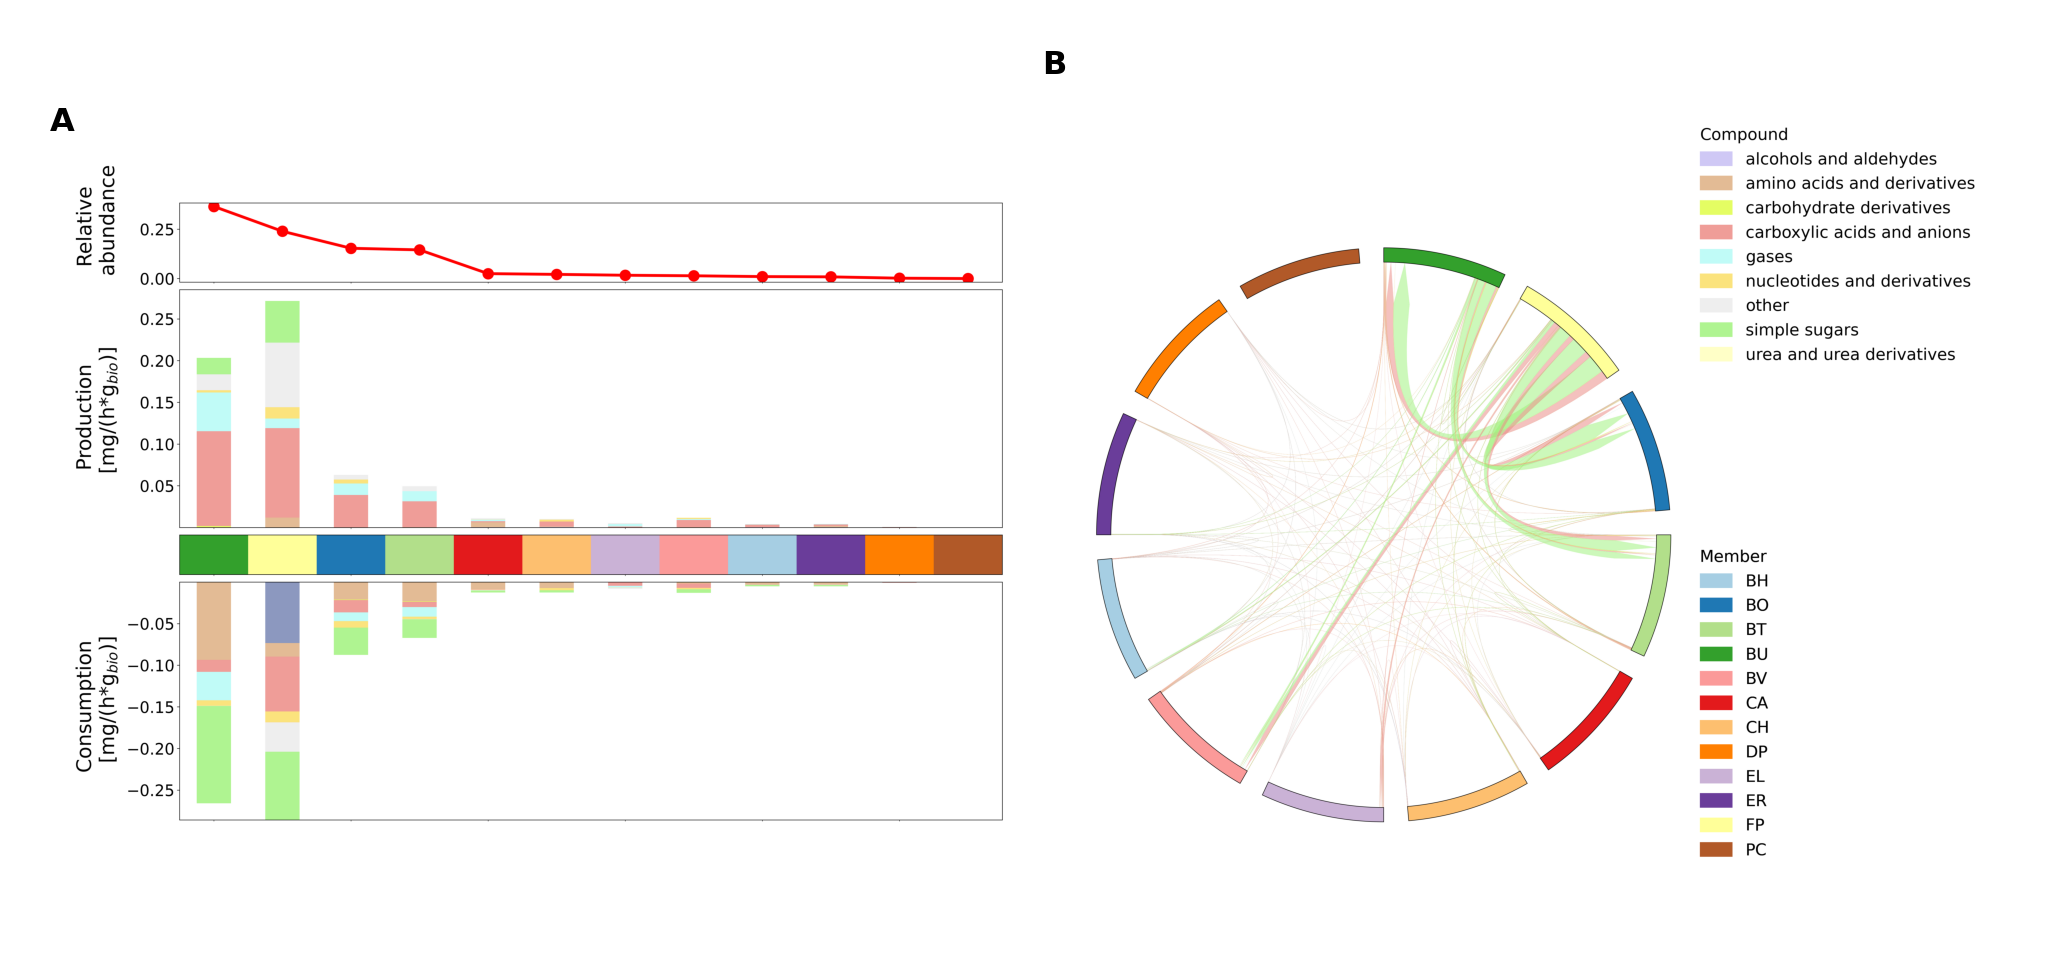

In [7]:
sim_results = simulation_dict["steadiercom"]["SteadierCom - Fixed growth & abundance"].copy()
sim_results["super_class"] = sim_results["compound"].map(agora_super_class_map)

sim_inter_res = sim_results.query("receiver != 'environment' & donor != 'environment'")

steadiercom_samples_plotting.combined_figure(sim_results,experimental_abundance,member2color_dict,"NONE",path = "../figures/circos/",move_legend=0)

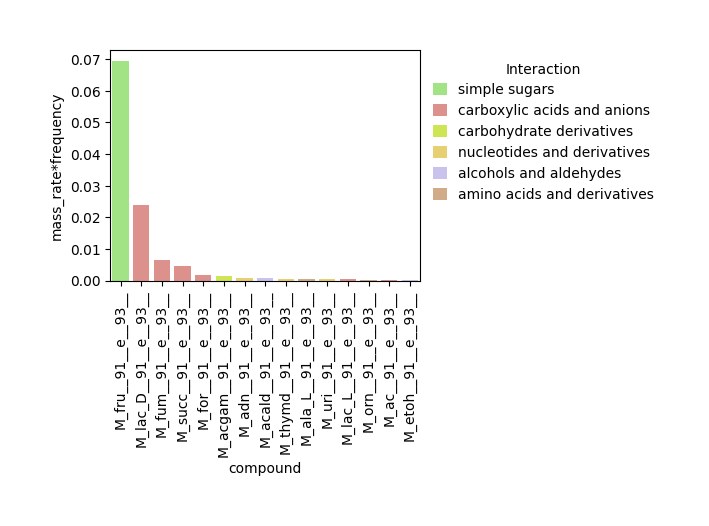

In [8]:
df = (
    sim_inter_res
    .groupby(by=["super_class","compound"])["mass_rate*frequency"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
    )


fig,ax = plt.subplots(1,1,figsize=(4,3))
sns.barplot(df.head(15),x="compound",y="mass_rate*frequency",hue="super_class",palette=metclass2color_dict,ax=ax)

ax.tick_params(axis='x', rotation=90)

sns.move_legend(ax, "upper left",title="Interaction" ,bbox_to_anchor=(1.0, 1.0),)

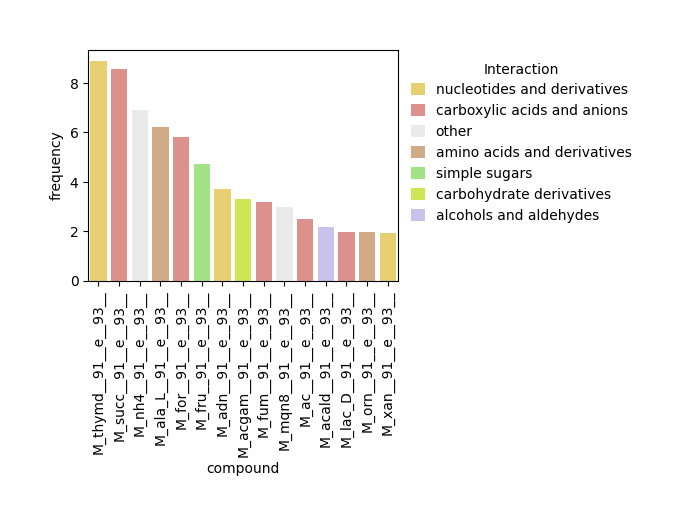

In [9]:
df = (
    sim_inter_res
    .groupby(by=["super_class","compound"])["frequency"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
    )

fig,ax = plt.subplots(1,1,figsize=(4,3))
sns.barplot(df.head(15),x="compound",y="frequency",hue="super_class",palette=metclass2color_dict,ax=ax)

ax.tick_params(axis='x', rotation=90)

sns.move_legend(ax, "upper left",title="Interaction" ,bbox_to_anchor=(1.0, 1.0),)

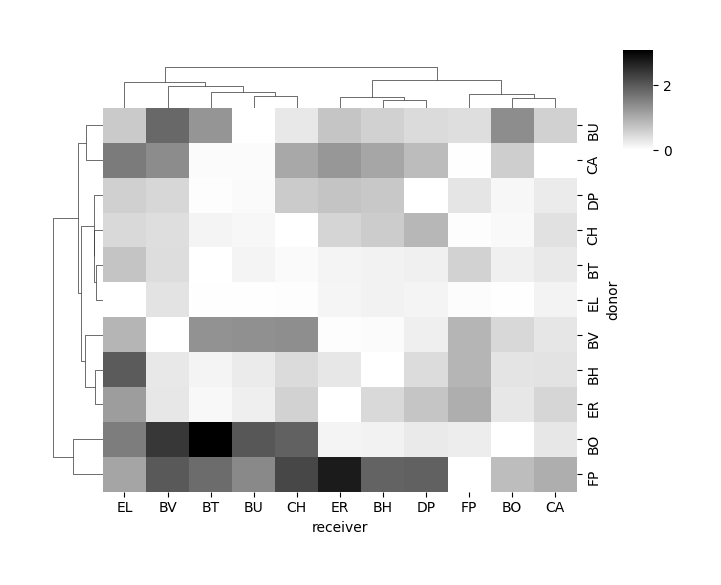

In [10]:
df = (
    sim_inter_res
    .groupby(by=["donor","receiver"])["frequency"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
    )
df2 = df.pivot_table(index=["receiver"],columns=["donor"],values="frequency").fillna(0)

g = sns.clustermap(df2.T,cmap="binary",method="ward",figsize=(6,5),dendrogram_ratio=0.1,cbar_pos=(0.98,0.8,0.05,0.2),)

### SteadierCom vs SteadyCom: Proteome constraints constrain the metabolic fluxes 
*Description*: Scatter plot of aggregate fluxes in SteadierCom and SteadyCom

*Main target*: Show how the fluxes are more constrained in SteadierCom

## Interactions (frequency) - SMETANA vs SteadierCom

*Description*: Comparing SMETANA and SteadierCom with exo-metabolomics data.

*Main target*: Show the difference between predicted important reactions in SMETANA and SteadierCom - for SteadierCom focus on frequency

### Per compound-class analysis: donor-compound-receiver (Triplets)

**combine simulated data**

In [11]:

# merge smetana and steadiercom results
merged_sim = processing.merge_smetana_steadiercom(smetana_all.copy(),
                                                  steadiercom_results_all.copy(),
                                                  )

# add super class to merged results
merged_sim["super_class"] = merged_sim.compound.map(agora_super_class_map)

In [12]:

# add quantiles to the merged simulation results for plotting error bars
df_stats = processing.add_quantiles(merged_sim)
sim_data_columns = ["steadiercom_median","steadiercom_q25","steadiercom_q75","smetana_median","smetana_q25","smetana_q75"]

# annotate with the experimental data (met not measured, supported, not supported)
exp_thresh = 0.5
df_merge = processing.add_metabolomics(
    df_stats,
    metabolomics,
    metid2metname,
    sim_data_columns,
    exp_thresh=exp_thresh
)

#### Scatterplot - overlap with metabolomics data

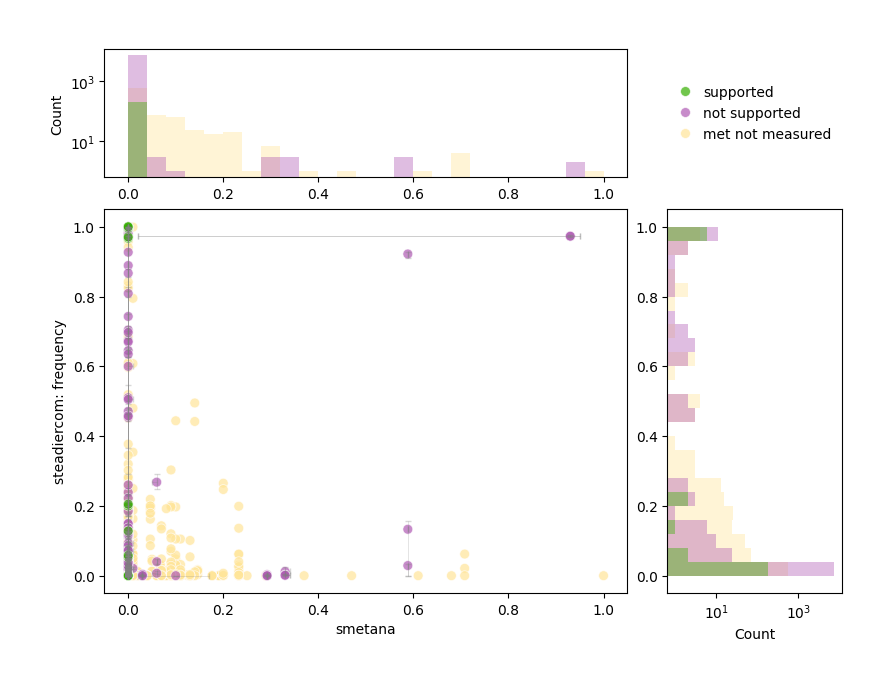

In [13]:
fig, axs = plotting.plot_triplets_scatter(df_merge)

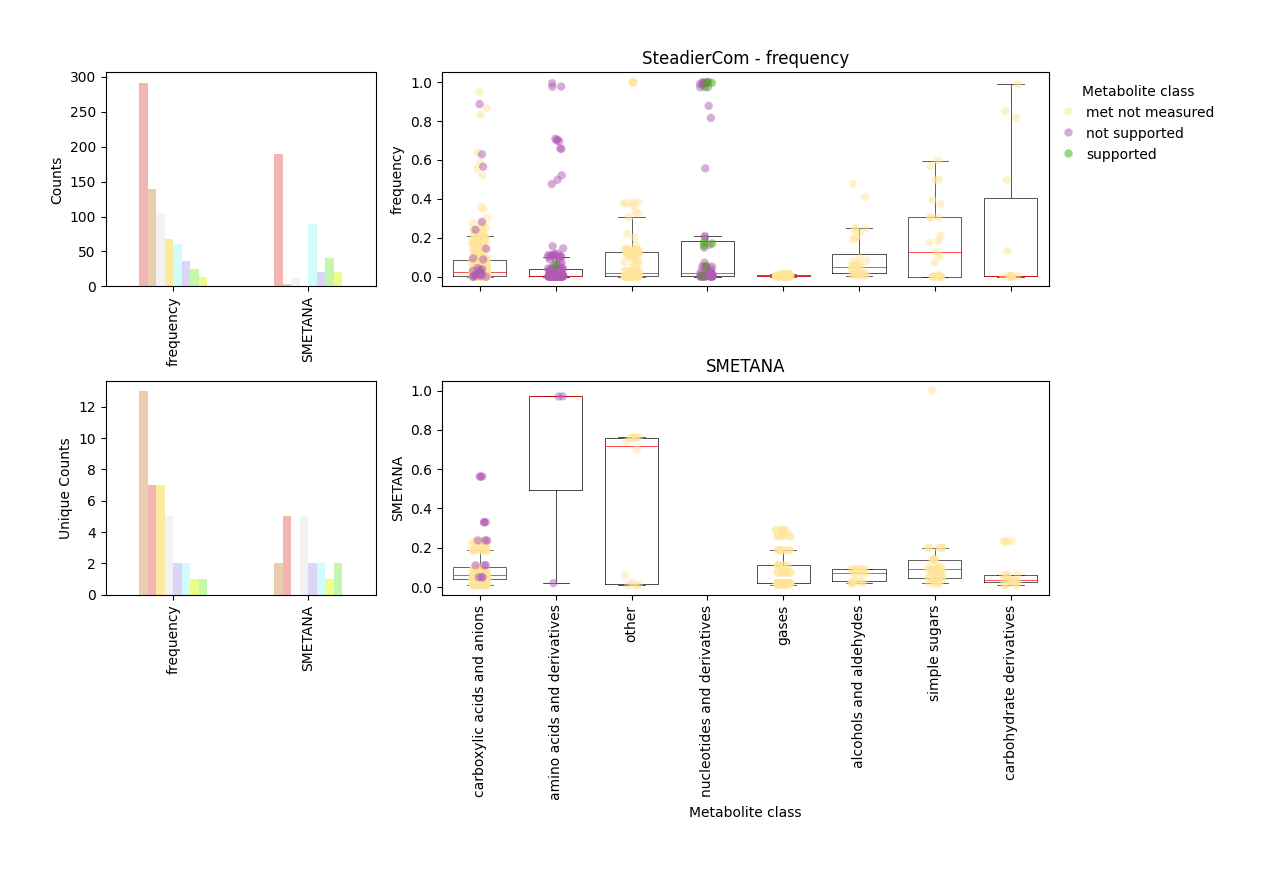

In [14]:
df_merge = processing.add_metabolomics(
    merged_sim.query("community == 'NONE'"),
    metabolomics,
    metid2metname,
    [],
    exp_thresh=exp_thresh
)
fig,axs = plotting.plot_triplets_violin(df_merge,metclass2color_dict,threshold=1e-6)

## SteadierCom prediction of competition and cooperation in comparison to predicted gLV coefficients

#### Calculate the score for competition and cooperation

In [15]:
df_merged_unfiltered1 = processing_glv.process_simulation_results(steadiercom_results_all, glv_data, method_comp=1)
df_merged_unfiltered2 = processing_glv.process_simulation_results(steadiercom_results_all, glv_data, method_comp=2)
df_merged_unfiltered3 = processing_glv.process_simulation_results(steadiercom_results_all, glv_data, method_comp=3)

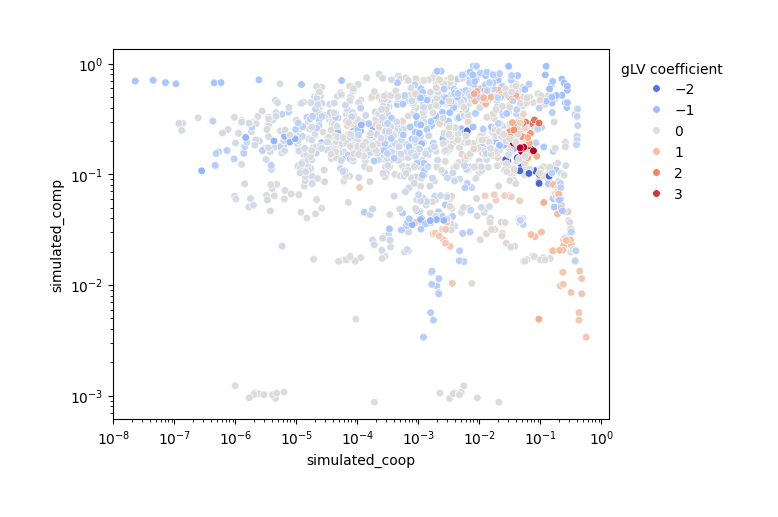

In [16]:
from matplotlib.colors import TwoSlopeNorm
df_merged = df_merged_unfiltered2.copy()
values = df_merged["experimental"]

# Normalize colors so that 0 is the center
norm = TwoSlopeNorm(
    vmin=values.min(),
    vcenter=0,
    vmax=values.max()
)
palette=mpl.colormaps["coolwarm"]

fig,ax = plt.subplots(1,1)

sns.scatterplot(ax=ax,
                data=df_merged,
                x="simulated_coop",
                y="simulated_comp",
                hue="experimental",
                palette=palette,
                hue_norm=norm,
                s=30
)
ax.set_xscale("log")
ax.set_yscale("log")
sns.move_legend(ax, "upper left", bbox_to_anchor=(1.0, 1.0),title="gLV coefficient")

### Plot of distribution around median 

In [17]:
df_median_stats = df_merged_unfiltered2.dropna().reset_index().groupby(["member_second","member_main"]).agg(coop_median = ("simulated_coop","median"),
                                                                                 coop_q25 = ("simulated_coop", lambda x: np.percentile(x, 25)),
                                                                                 coop_q75 = ("simulated_coop", lambda x: np.percentile(x, 75)),
                                                                                 comp_median = ("simulated_comp","median"),
                                                                                 comp_q25 = ("simulated_comp", lambda x: np.percentile(x, 25)),
                                                                                 comp_q75 = ("simulated_comp", lambda x: np.percentile(x, 75)),
                                                                                 experimental = ("experimental","mean")
                                                                                )

/Users/idunmariaburgos/SteadierCom/case_studies/notebooks/../functions/analysis/compare_glv/plotting.py:122: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.violinplot(df_merged,x=x,y=y,hue="exp_categories",ax=ax,palette="coolwarm",cut=0,alpha=0.5,linecolor="gray",inner_kws=dict(box_width=8, whis_width=1,alpha=0.8),zorder=0,legend=(comp_coop=="coop_median"))
/Users/idunmariaburgos/SteadierCom/case_studies/notebooks/../functions/analysis/compare_glv/plotting.py:123: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(df_merged,x=x,y=y,hue="exp_categories",palette="coolwarm",ax=ax,alpha=0.5,linewidth=0.5,edgecolor="gray",size=4,jitter=0.2,zorder=1)
/Users/idunmariaburgos/SteadierCom/case_studies/notebooks/../functions/analysis/compare_glv/plotting.py:122: FutureWarning: Use "auto" to set automatic grayscale colors. From v0

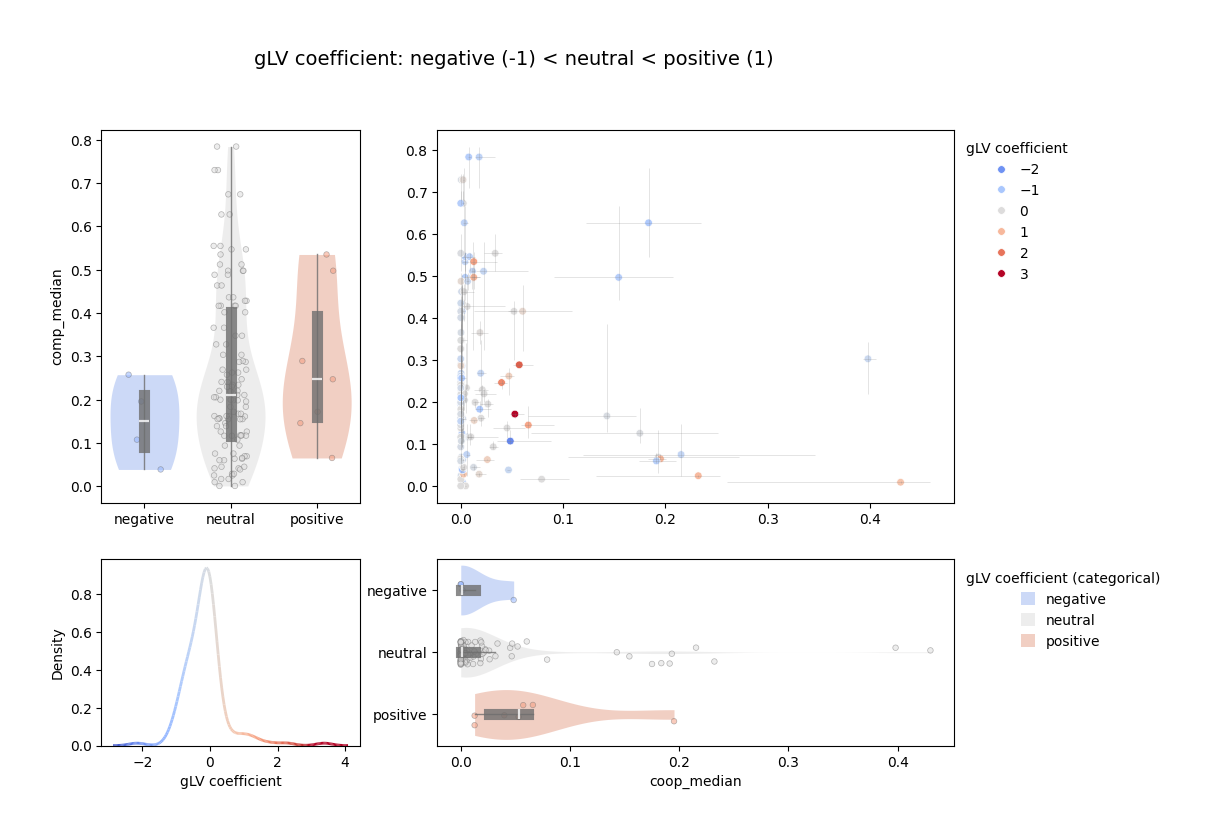

In [18]:
df_merged = processing_glv.make_glv_categories(df_median_stats, glv_cutoff=1)
plotting_glv.plot_interactions_median(df_merged,title="gLV coefficient: negative (-1) < neutral < positive (1)")

/Users/idunmariaburgos/SteadierCom/case_studies/notebooks/../functions/analysis/compare_glv/plotting.py:122: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.violinplot(df_merged,x=x,y=y,hue="exp_categories",ax=ax,palette="coolwarm",cut=0,alpha=0.5,linecolor="gray",inner_kws=dict(box_width=8, whis_width=1,alpha=0.8),zorder=0,legend=(comp_coop=="coop_median"))
/Users/idunmariaburgos/SteadierCom/case_studies/notebooks/../functions/analysis/compare_glv/plotting.py:123: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(df_merged,x=x,y=y,hue="exp_categories",palette="coolwarm",ax=ax,alpha=0.5,linewidth=0.5,edgecolor="gray",size=4,jitter=0.2,zorder=1)
/Users/idunmariaburgos/SteadierCom/case_studies/notebooks/../functions/analysis/compare_glv/plotting.py:122: FutureWarning: Use "auto" to set automatic grayscale colors. From v0

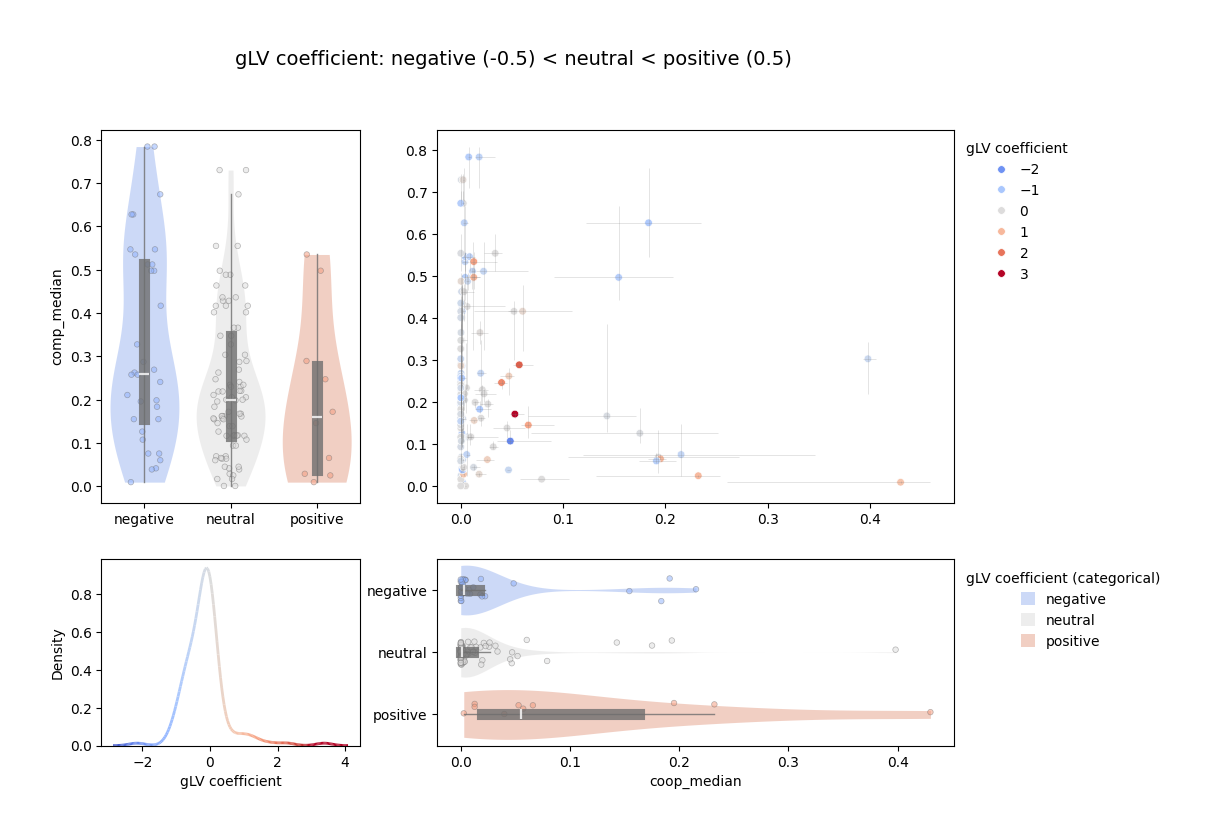

In [19]:
df_merged = processing_glv.make_glv_categories(df_median_stats, glv_cutoff=0.5)
plotting_glv.plot_interactions_median(df_merged,title="gLV coefficient: negative (-0.5) < neutral < positive (0.5)")

# Abundance

In [20]:
exp_abundance_df = data.load_experimental_abundance()
cmap = ['#a6cee3','#1f78b4', '#b2df8a', '#33a02c', '#fb9a99','#e31a1c', '#fdbf6f', '#ff7f00', '#cab2d6', '#6a3d9a', '#ffff99', '#b15928']
member_colors = dict(zip(exp_abundance_df.columns,cmap))

INFO     | Loading experimental abundances for all communities from ../data/Venturelli2018/generated/communities_steadiercom/


### SteadierCom

**Load and process data**

In [21]:
# Load experimental results

exp_abundance_df_reshaped = exp_abundance_df.stack().reset_index()
exp_abundance_df_reshaped.rename(columns={0:"relative_abundance"}, inplace=True)

# Load SteadyCom results
steadiercom_abundance_df, steadycom_abundance_df = data.load_simulated_abundance()

# Merge simulated and experimental data
joined_spec = pd.merge(steadiercom_abundance_df, exp_abundance_df_reshaped, on=["community","member"], suffixes=("_sim","_exp"))

**Plot**

Text(0, 0.5, '')

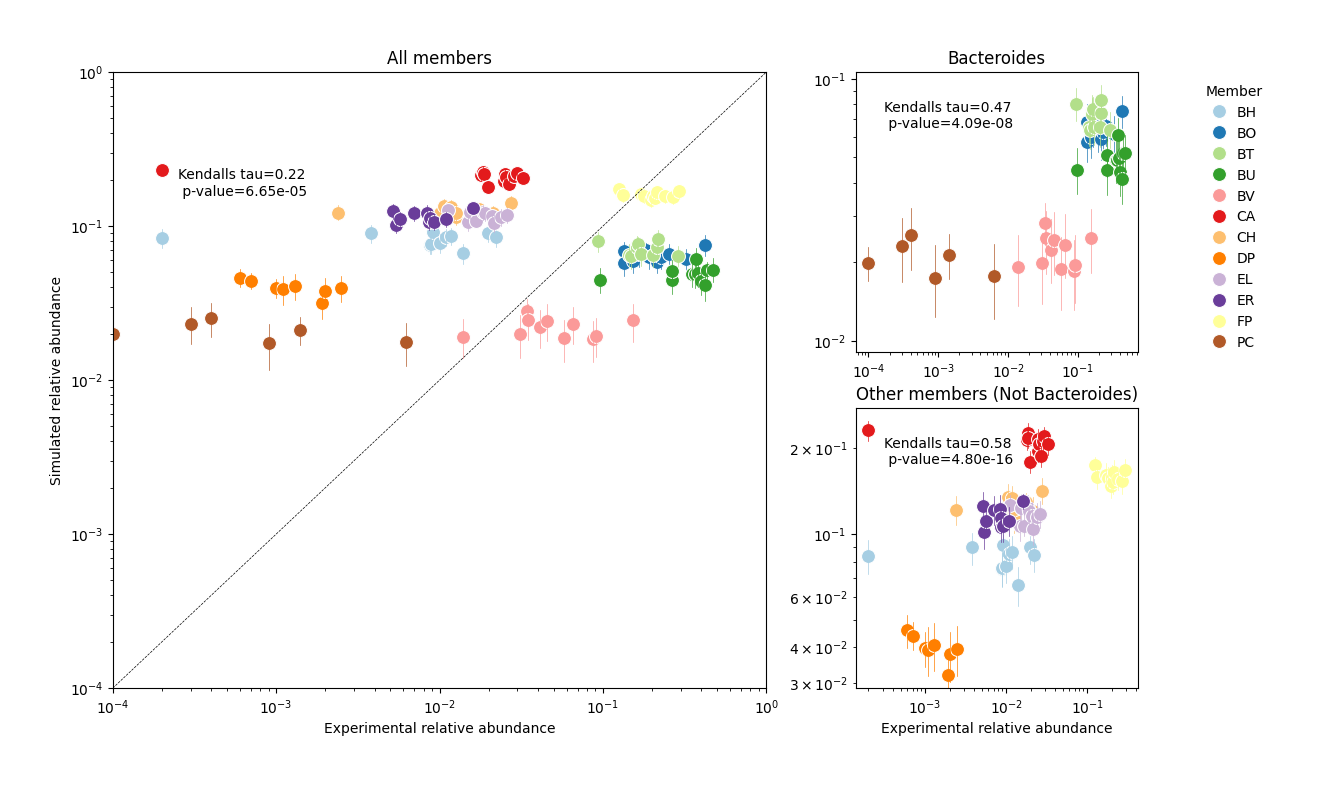

In [22]:
fig = plt.figure(figsize=(15, 8))#, constrained_layout=True)

gs = fig.add_gridspec(
    2, 7,
    wspace=1.0, 
    width_ratios=[1, 1, 1, 1, 1, 1, 0.5],
)

ax1 = fig.add_subplot(gs[:, :4])
ax2 = fig.add_subplot(gs[0, 4:6])
ax3 = fig.add_subplot(gs[1, 4:6])
ax_leg = fig.add_subplot(gs[:, 6])

ax1 = plotting_abundance.plot_scatter_steadiercom(
    joined_spec,
    ax1,
    "All members",
    member_colors,
    legend=True,
)
ax1.axline((0, 0), slope=1, color='black', linestyle='--')
ax1.set_ylim(1e-4,1)
ax1.set_xlim(1e-4,1)

bacteroides = ["BO","BT","BU","BV","PC"]
not_bacteroides = [m for m in joined_spec.member.unique() if m not in bacteroides]
joined_spec_new = joined_spec[joined_spec.member.isin(bacteroides)].copy()
ax2 = plotting_abundance.plot_scatter_steadiercom(joined_spec_new,          
                                                   ax2,
                                                   "Bacteroides",
                                                    member_colors,
                                                   )


joined_spec_new = joined_spec[~joined_spec.member.isin(bacteroides)].copy()
ax3 = plotting_abundance.plot_scatter_steadiercom(joined_spec_new,
                                                  ax3,
                                                  "Other members (Not Bacteroides)",
                                                  member_colors,)


# move legend from ax1 to dedicated legend axis
handles, labels = ax1.get_legend_handles_labels()
if ax1.legend_ is not None:
    ax1.legend_.remove()

ax_leg.axis("off")
ax_leg.legend(handles, labels, loc="upper right", title="Member", frameon=False)


for ax in (ax1, ax2, ax3):
    ax.set_yscale("log")
    ax.set_xscale("log")
    ax.set_ylabel("Simulated relative abundance")
    ax.set_xlabel("Experimental relative abundance")

ax2.set_xlabel("")
ax2.set_ylabel("")
ax3.set_ylabel("")



### SteadyCom

**Load and process data**

In [23]:
steadycom_abundance_reshaped = (
    pd.melt((steadycom_abundance_df.fillna(0).rename_axis("community").reset_index()),
        id_vars="community",
        var_name="member",
        value_name="relative_abundance")
        )
# Merge simulated and experimental data
joined_spec = pd.merge(steadycom_abundance_reshaped, exp_abundance_df_reshaped, on=["community","member"], suffixes=("_sim","_exp"))

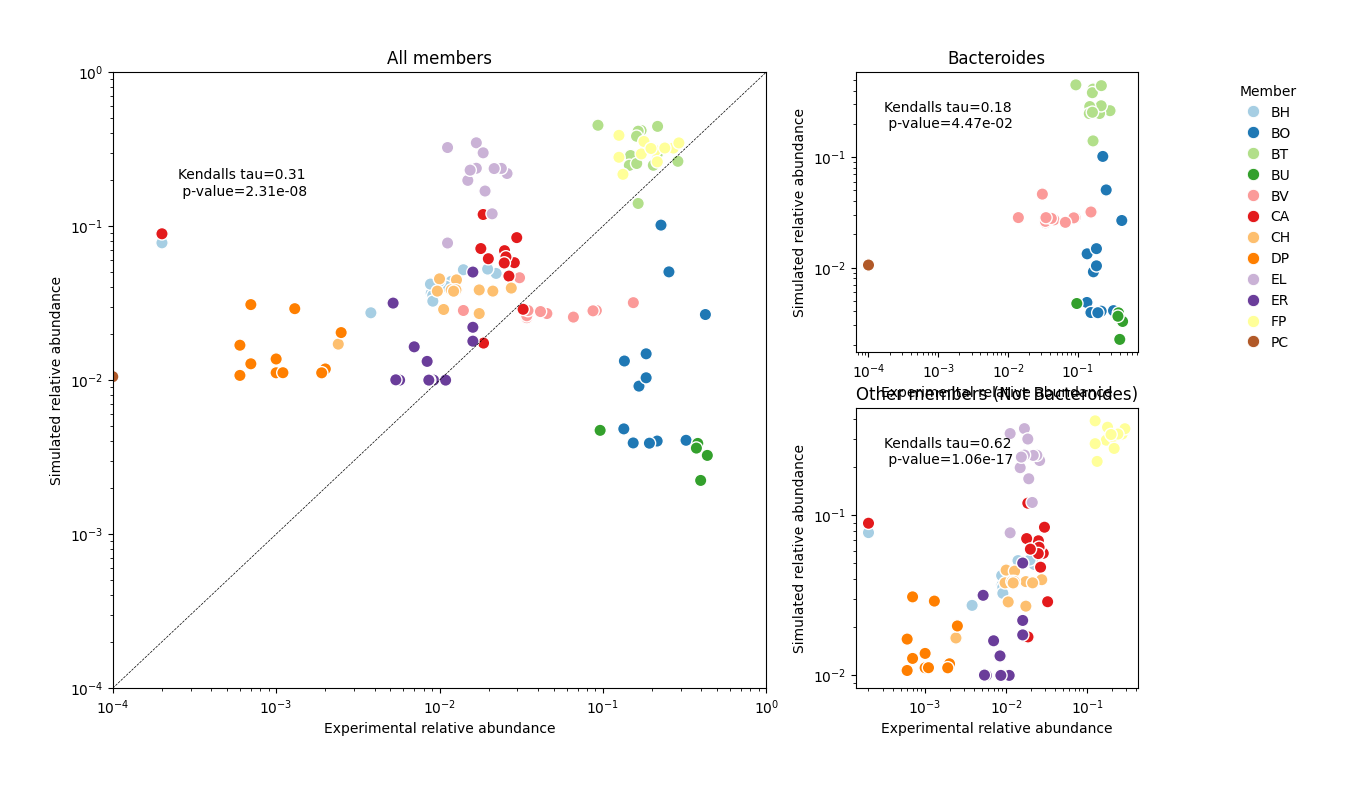

In [24]:
fig = plt.figure(figsize=(15, 8))#, constrained_layout=True)

gs = fig.add_gridspec(
    2, 7,
    wspace=1.0, 
    width_ratios=[1, 1, 1, 1, 1, 1, 0.5],
)

ax1 = fig.add_subplot(gs[:, :4])
ax2 = fig.add_subplot(gs[0, 4:6])
ax3 = fig.add_subplot(gs[1, 4:6])
ax_leg = fig.add_subplot(gs[:, 6])

ax1 = plotting_abundance.plot_scatter_steadycom(joined_spec,
                               ax1,
                               "All members",
                               member_colors,
                               legend=True)
ax1.axline((0, 0), slope=1, color='black', linestyle='--')
ax1.set_ylim(1e-4,1)
ax1.set_xlim(1e-4,1)

bacteroides = ["BO","BT","BU","BV","PC"]
not_bacteroides = [m for m in joined_spec.member.unique() if m not in bacteroides]
joined_spec_new = joined_spec[joined_spec.member.isin(bacteroides)].copy()
ax2 = plotting_abundance.plot_scatter_steadycom(joined_spec_new,
                               ax2,
                               "Bacteroides",
                               member_colors)

joined_spec_new = joined_spec[~joined_spec.member.isin(bacteroides)].copy()
ax3 = plotting_abundance.plot_scatter_steadycom(joined_spec_new,
                               ax3,
                               "Other members (Not Bacteroides)",
                               member_colors)


# move legend from ax1 to dedicated legend axis
handles, labels = ax1.get_legend_handles_labels()
if ax1.legend_ is not None:
    ax1.legend_.remove()

ax_leg.axis("off")
ax_leg.legend(handles, labels, loc="upper left", title="Member", frameon=False)


for ax in (ax1, ax2, ax3):
    ax.set_yscale("log")
    ax.set_xscale("log")
    ax.set_ylabel("Simulated relative abundance")
    ax.set_xlabel("Experimental relative abundance")


<Axes: xlabel='member'>

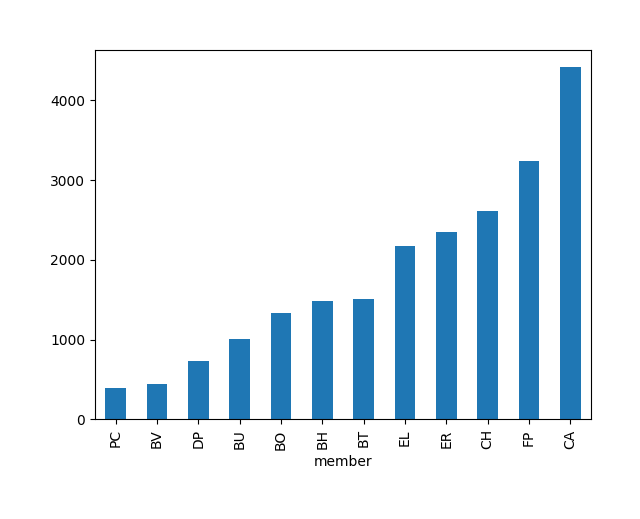

In [25]:
steadiercom_abundance_df.query("relative_abundance > 0.99").groupby("member")["relative_abundance"].count().sort_values().plot(kind="bar")

### Overall statistics

In [26]:
def pos_neg_class_exp(metabolomics, metid2metname,exp_thresh=1):
    exp_triplets_df  = make_metabolomics_triplets(metabolomics, exp_thresh=exp_thresh)
   
    metname_translate_AGORA = metid2metname.values()
    n_exp_thresh = (
        exp_triplets_df
        .query("compound_name in @metname_translate_AGORA")
        .groupby("exp_interact")
        .size()
        )

    return {
        "Negative (No interaction)": n_exp_thresh[False],
        "Positive (Inferred interaction)": n_exp_thresh[True],
        
    }

def overlap_statistic(simulation_dict,exp_thresh=1):

    smetana_results = simulation_dict["smetana"]["SMETANA"].copy()
    steadiercom_results = simulation_dict["steadiercom"]["SteadierCom - Fixed growth & abundance"].copy()

    exp_triplets_df  = make_metabolomics_triplets(metabolomics, exp_thresh=exp_thresh)
    
    smetana_merged_sim_exp = merge_metabolomics(smetana_results,exp_triplets_df,metid2metname,[])
    smetana_stats = smetana_merged_sim_exp[~smetana_merged_sim_exp["smetana"].isna()].groupby("experimental_support").size()

    steadiercom_merged_sim_exp = merge_metabolomics(steadiercom_results,exp_triplets_df,metid2metname,[])
    steadiercom_stats = steadiercom_merged_sim_exp[~steadiercom_merged_sim_exp["frequency"].isna()].groupby("experimental_support").size()

    return steadiercom_stats, smetana_stats


#### Calculate overlap

In [27]:
res_exp_dict = {}
res_overlap_steadiercom = {}
res_overlap_smetana = {}
for exp_thresh in [round(value,2) for value in np.linspace(0.1,1.1, num=6)]:
    res_exp_dict[exp_thresh] = pos_neg_class_exp(metabolomics, metid2metname,exp_thresh=exp_thresh)

    steadiercom_stats,smetana_stats = overlap_statistic(simulation_dict, exp_thresh=exp_thresh)
    res_overlap_steadiercom[exp_thresh] = steadiercom_stats
    res_overlap_smetana[exp_thresh] = smetana_stats

NameError: name 'make_metabolomics_triplets' is not defined

In [ ]:

stats = pd.DataFrame(res_exp_dict).T.reset_index().rename(columns={"index":"exp_thresh"}).melt(id_vars=["exp_thresh"], var_name="class", value_name="count")

steadiercom_stats = pd.DataFrame(res_overlap_steadiercom).T.reset_index().rename(columns={"index":"exp_thresh"})
steadiercom_stats = steadiercom_stats.melt(id_vars=["exp_thresh"], var_name="overlap", value_name="count")
smetana_stats = pd.DataFrame(res_overlap_smetana).T.reset_index().rename(columns={"index":"exp_thresh"})
smetana_stats = smetana_stats.melt(id_vars=["exp_thresh"], var_name="overlap", value_name="count")

[INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
[INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


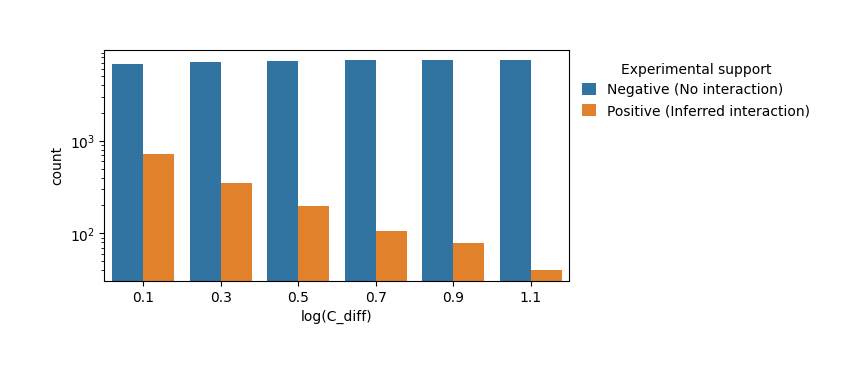

In [ ]:

fig,ax = plt.subplots(1,1,figsize=(6,3))
ax = sns.barplot(data=stats,x="exp_thresh", y="count", hue="class")
sns.move_legend(ax, "upper left", bbox_to_anchor=(1.0, 1.0),title="Experimental support")
ax.set_xlabel("log(C_diff)")
ax.set_yscale("log")

#### Overlap between SMETANA and SteadierCom

Text(0, 0.5, 'Count of interactions')

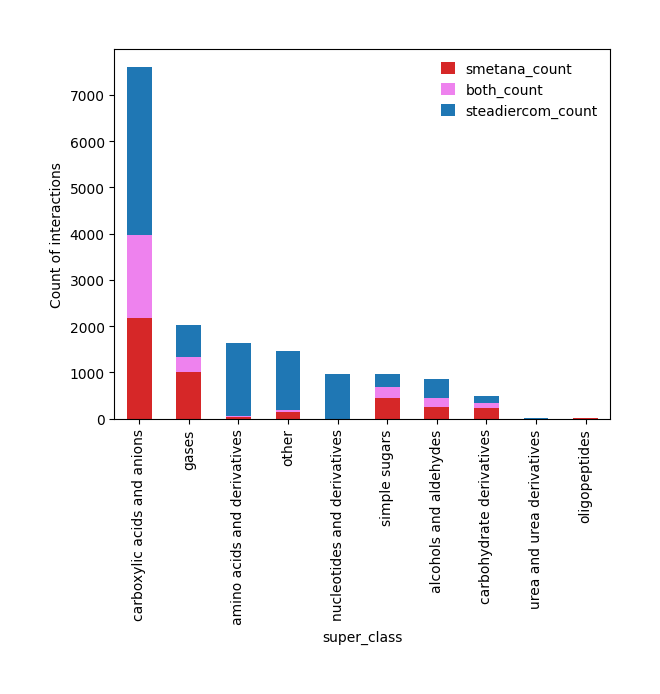

In [ ]:
mask_both = merged_sim[["smetana", "frequency"]].notna().all(axis=1)

result = merged_sim.groupby("super_class").agg(
    smetana_count=("smetana", "count"),
    steadiercom_count=("frequency", "count"),
    both_count=("smetana", lambda x: mask_both.loc[x.index].sum())
)

order_mets = result.sum(axis=1).sort_values(ascending=False).index
order_groups = ["smetana_count","both_count","steadiercom_count"]
ax = result.loc[order_mets,order_groups].plot.bar(stacked=True,color=["tab:red","violet","tab:blue"])
ax.set_ylabel("Count of interactions")

Text(0, 0.5, 'Count of interactions')

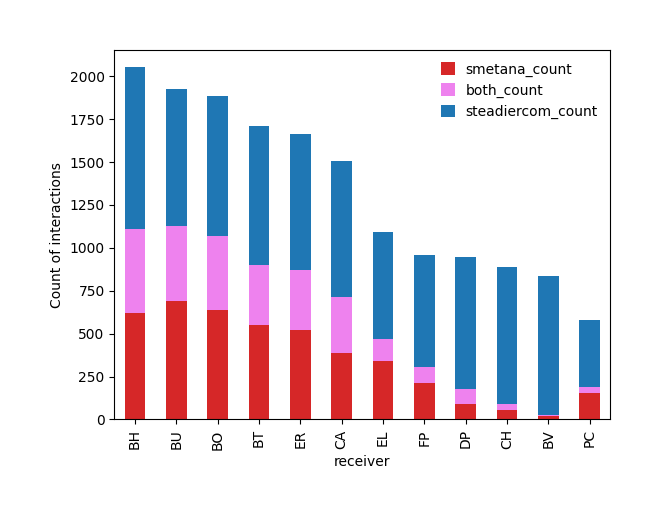

In [ ]:
mask_both = merged_sim[["smetana", "frequency"]].notna().all(axis=1)

result = merged_sim.groupby("receiver").agg(
    smetana_count=("smetana", "count"),
    steadiercom_count=("frequency", "count"),
    both_count=("smetana", lambda x: mask_both.loc[x.index].sum())
)

order_mets = result.sum(axis=1).sort_values(ascending=False).index
order_groups = ["smetana_count","both_count","steadiercom_count"]
ax = result.loc[order_mets,order_groups].plot.bar(stacked=True,color=["tab:red","violet","tab:blue"])
ax.set_ylabel("Count of interactions")
